# Carthage Eye: fire-day model, end-to-end test

This notebook reproduces the fire results published on the methods page, from the example input files in `results/`.

**Question.** On a summer day, how likely is a NASA FIRMS fire detection (confidence 50 or higher) in a northern Tunisian governorate? It is a probability for a governorate-day. It does not say where or when a fire starts.

**Steps.** (1) Train on 2003-2020 and test on 2021-2025 with reanalysis weather. (2) Score the same model on archived Open-Meteo forecasts, 1 to 7 days ahead, summers 2024-2025.

**Input (examples).** `results/fire_training_table_2003_2025.csv` (made by `scripts/08_fire_training_table.js`) and `results/forecast_leadtime_2024_2025.csv` (made by `scripts/10_forecast_test_tool.html`).
**Output.** `results/notebook_output_models.csv`, `results/notebook_output_leadtime.csv`, `results/notebook_output_auc_by_lead.png`.

Run from the repository root: `pip install -r requirements.txt`, then open and run all cells. Takes under a minute. No credentials or restricted data are needed.

Values can differ in the third decimal from the methods page, because the table in `results/` is rounded to 3 decimals.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss

d = pd.read_csv('results/fire_training_table_2003_2025.csv')   # example input
print(d.shape, 'rows;', d.gov.nunique(), 'governorates;', d.year.min(), '-', d.year.max())
print(d.head(3).to_string(index=False))
print('Share of governorate-days with a fire detection:', round(d.fire.mean(), 4))

(30866, 11) rows; 11 governorates; 2003 - 2025
      gov       date  year  doy   tmax     rh  rain   wind  rain7  rain30  fire
   Ariana 2003-06-01  2003  152 26.789 49.062 0.001 12.081 10.955  15.485     0
     Beja 2003-06-01  2003  152 30.275 33.048 0.001 10.111 13.476  23.967     0
Ben Arous 2003-06-01  2003  152 28.560 39.853 0.001  8.476 11.415  15.923     0
Share of governorate-days with a fire detection: 0.0532


In [2]:
d['doy2'] = d.doy ** 2
d['rain_log'] = np.log1p(d.rain); d['r7l'] = np.log1p(d.rain7); d['r30l'] = np.log1p(d.rain30)
tr, te = d[d.year <= 2020], d[d.year >= 2021]          # train 2003-2020, test 2021-2025
y = te.fire.values
W = ['tmax', 'rh', 'rain_log', 'wind', 'r7l', 'r30l']; D = ['doy', 'doy2']

def fit(num, gov):
    parts = ([('n', StandardScaler(), num)] if num else []) + ([('g', OneHotEncoder(handle_unknown='ignore'), ['gov'])] if gov else [])
    cols = num + (['gov'] if gov else [])
    return make_pipeline(ColumnTransformer(parts), LogisticRegression(max_iter=3000)).fit(tr[cols], tr.fire), cols

def top10(y, p):                                        # share of all fires on the 10% highest-rated days
    k = int(round(len(p) * 0.1)); i = np.argsort(-p)[:k]; return y[i].sum() / y.sum()

m_doy, c_doy = fit(D, 0); m_gd, c_gd = fit(D, 1); m_v2, c_v2 = fit(W + D, 1)
rule = ((te.tmax >= 35) & (te.rh <= 25) & (te.rain < 5)).values      # version 1 rule used in the app
P = {'version 1 rule (rates from test years)': np.where(rule, y[rule].mean(), y[~rule].mean()),
     'day of year only': m_doy.predict_proba(te[c_doy])[:, 1],
     'governorate + day of year': m_gd.predict_proba(te[c_gd])[:, 1],
     'governorate + weather + day of year (version 2)': m_v2.predict_proba(te[c_v2])[:, 1]}
res = pd.DataFrame([{'model': n, 'auc': round(roc_auc_score(y, p), 3), 'brier': round(brier_score_loss(y, p), 4),
                     'share_of_fires_in_top10pct_days': round(top10(y, p), 2)} for n, p in P.items()])
res.to_csv('results/notebook_output_models.csv', index=False)
print('Test years 2021-2025:', len(te), 'governorate-days,', int(y.sum()), 'with a fire detection')
print(res.to_string(index=False))

Test years 2021-2025: 6710 governorate-days, 394 with a fire detection
                                          model   auc  brier  share_of_fires_in_top10pct_days
         version 1 rule (rates from test years) 0.540 0.0551                             0.14
                               day of year only 0.625 0.0547                             0.13
                      governorate + day of year 0.770 0.0513                             0.43
governorate + weather + day of year (version 2) 0.798 0.0489                             0.46


In [3]:
f = pd.read_csv('results/forecast_leadtime_2024_2025.csv')      # example input: archived forecasts, 1-7 days ahead
f['date'] = pd.to_datetime(f.date)
l1 = f[f.lead == 1][['gov', 'date', 'rain_lead1']].drop_duplicates().sort_values(['gov', 'date'])
l1['rain7'] = l1.groupby('gov').rain_lead1.transform(lambda s: s.shift(1).rolling(7, min_periods=7).sum())
l1['rain30'] = l1.groupby('gov').rain_lead1.transform(lambda s: s.shift(1).rolling(30, min_periods=30).sum())
f = f.merge(l1[['gov', 'date', 'rain7', 'rain30']], on=['gov', 'date'])
f['rh'] = (100 * np.exp(17.625 * f.dew / (243.04 + f.dew)) / np.exp(17.625 * f.tmax / (243.04 + f.tmax))).clip(upper=100)
f['doy'] = f.date.dt.dayofyear; f['doy2'] = f.doy ** 2
f['rain_log'] = np.log1p(f.rain); f['r7l'] = np.log1p(f.rain7); f['r30l'] = np.log1p(f.rain30)
f = f[(f.date.dt.month >= 6) & (f.date.dt.month <= 9)].dropna(subset=['rain7', 'rain30'])
f['dstr'] = f.date.dt.strftime('%Y-%m-%d')
lab = d[d.year >= 2024][['gov', 'date', 'fire']].rename(columns={'date': 'dstr'})   # fire labels for the same days
f = f.merge(lab, on=['gov', 'dstr'])
rows = []
for L in range(1, 8):
    x = f[f.lead == L]; yy = x.fire.values
    p = m_v2.predict_proba(x[c_v2])[:, 1]; q = m_gd.predict_proba(x[c_gd])[:, 1]
    rows.append({'lead_days': L, 'auc_version2': round(roc_auc_score(yy, p), 3), 'auc_gov_doy_only': round(roc_auc_score(yy, q), 3),
                 'brier_version2': round(brier_score_loss(yy, p), 4), 'brier_gov_doy_only': round(brier_score_loss(yy, q), 4),
                 'mean_predicted': round(p.mean(), 3), 'observed_rate': round(yy.mean(), 3)})
lead = pd.DataFrame(rows); lead.to_csv('results/notebook_output_leadtime.csv', index=False)
print(len(x), 'governorate-days per lead time,', int(yy.sum()), 'with a fire detection')
print(lead.to_string(index=False))

2684 governorate-days per lead time, 138 with a fire detection
 lead_days  auc_version2  auc_gov_doy_only  brier_version2  brier_gov_doy_only  mean_predicted  observed_rate
         1         0.826              0.83          0.0435              0.0439           0.064          0.051
         2         0.824              0.83          0.0434              0.0439           0.064          0.051
         3         0.827              0.83          0.0433              0.0439           0.064          0.051
         4         0.829              0.83          0.0433              0.0439           0.063          0.051
         5         0.824              0.83          0.0428              0.0439           0.069          0.051
         6         0.823              0.83          0.0428              0.0439           0.068          0.051
         7         0.808              0.83          0.0468              0.0439           0.091          0.051


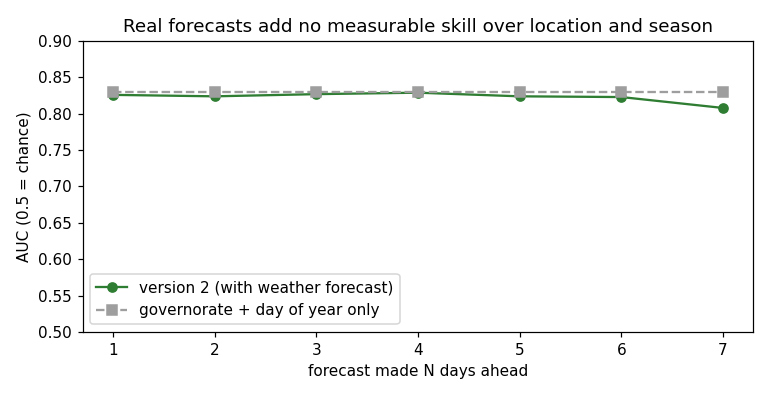

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(lead.lead_days, lead.auc_version2, 'o-', label='version 2 (with weather forecast)', color='#2e7d32')
ax.plot(lead.lead_days, lead.auc_gov_doy_only, 's--', label='governorate + day of year only', color='#9e9e9e')
ax.set_xlabel('forecast made N days ahead'); ax.set_ylabel('AUC (0.5 = chance)'); ax.set_ylim(0.5, 0.9)
ax.set_title('Real forecasts add no measurable skill over location and season'); ax.legend(loc='lower left')
fig.tight_layout(); fig.savefig('results/notebook_output_auc_by_lead.png', dpi=130); plt.show()

**Reading the result.** Version 2 beats the version 1 rule at ranking days, but most of that skill comes from the governorate and the time of summer. With real archived forecasts, the weather inputs add no measurable skill over a model that knows only those two things, and version 2 is worse at 7 days. So version 2 is **not** used in the app. Limits: northern governorates only, FIRMS detections include crop burning, two summers for the forecast test (138 fire days), forecasts taken at one point per governorate. Full details: `methods.html`, section 5.